In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.stats import cov_loops, cov_vec, corr_from_cov
from quantlab.linalg_tools import ols_normal, ols_qr, ols_svd, pca_svd

r = log_returns(load_prices())
stocks = r.drop(columns="^GSPC")

In [2]:
X = np.random.default_rng(0).standard_normal((2500, 25))
print(np.allclose(cov_loops(X), cov_vec(X)), np.allclose(cov_vec(X), np.cov(X, rowvar=False)))
%timeit -n 1 -r 1 cov_loops(X)
%timeit cov_vec(X)
%timeit np.cov(X, rowvar=False)

True True
2.6 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
765 μs ± 50.2 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
906 μs ± 75.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [3]:
S = cov_vec(stocks.to_numpy())
print("symmetric:", np.allclose(S, S.T))
print("smallest eigenvalue:", np.linalg.eigvalsh(S).min())

S_short = cov_vec(stocks.to_numpy()[:10])   # 10 days, 25 assets
print("rank with 10 days and 25 assets:", np.linalg.matrix_rank(S_short))

print("corr matches pandas:", np.allclose(corr_from_cov(S), stocks.corr().to_numpy()))

symmetric: True
smallest eigenvalue: 4.4933152830296065e-05
rank with 10 days and 25 assets: 9
corr matches pandas: True


In [4]:
rng = np.random.default_rng(0)
a = rng.standard_normal(500)
beta = np.array([1.0, 1.0])
rows = []
for eps in [1e-2, 1e-4, 1e-6, 1e-8]:
    X = np.column_stack([a, a + eps * rng.standard_normal(500)])  # two almost identical columns
    y = X @ beta
    rows.append({
        "eps": eps,
        "cond_X": np.linalg.cond(X),
        "cond_XtX": np.linalg.cond(X.T @ X),
        **{f.__name__: np.linalg.norm(f(X, y) - beta) for f in (ols_normal, ols_qr, ols_svd)},
    })
pd.DataFrame(rows)

,eps,cond_X,cond_XtX,ols_normal,ols_qr,ols_svd
0,1.000000e-02,2.156382e+02,4.649981e+04,1.090688e-11,4.577567e-16,1.910100e-15
1,1.000000e-04,2.005569e+04,4.022307e+08,2.201556e-07,1.214473e-13,1.214473e-13
2,1.000000e-06,1.961572e+06,3.849847e+12,3.010887e-04,6.422722e-11,7.366795e-12
3,1.000000e-08,2.056219e+08,1.278919e+16,1.272792e+01,1.115848e-09,1.641021e-09


In [5]:
mkt = r["^GSPC"].to_numpy()
X_capm = np.column_stack([np.ones(len(mkt)), mkt])   # intercept + market return
y = r["AAPL"].to_numpy()

print("normal:", ols_normal(X_capm, y))
print("qr    :", ols_qr(X_capm, y))
print("svd   :", ols_svd(X_capm, y))
print("statsmodels:", sm.OLS(y, X_capm).fit().params)

betas = pd.Series({t: ols_qr(X_capm, r[t].to_numpy())[1] for t in stocks.columns}).sort_values()
betas.round(2)

normal: [6.10505585e-04 1.15315435e+00]
qr    : [6.10505585e-04 1.15315435e+00]
svd   : [6.10505585e-04 1.15315435e+00]
statsmodels: [6.10505585e-04 1.15315435e+00]


PG      0.50
PEP     0.51
KO      0.52
MCD     0.59
WMT     0.60
NEE     0.61
AMGN    0.79
UNH     0.80
XOM     0.83
GILD    0.83
CVX     0.89
NKE     0.91
UNP     0.91
HD      1.01
DIS     1.05
MSFT    1.09
CAT     1.11
AAPL    1.15
ORCL    1.19
CSCO    1.20
AMZN    1.26
WFC     1.26
INTC    1.29
JPM     1.39
BAC     1.48
dtype: float64

[0.386 0.094 0.06  0.051 0.046]


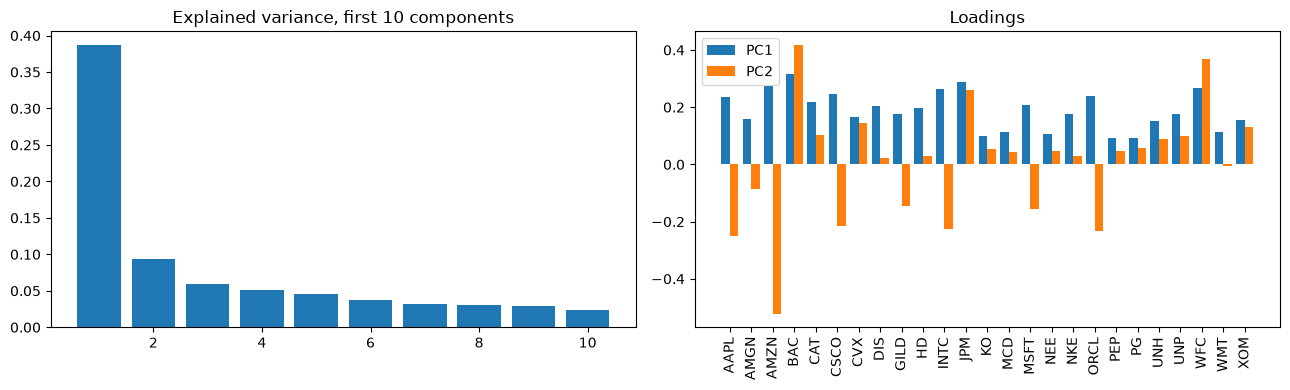

In [6]:
eigvals, Vt, scores = pca_svd(stocks.to_numpy())
if Vt[0].sum() < 0:          # signs are arbitrary; flip so the market factor reads positive
    Vt[0] = -Vt[0]
explained = eigvals / eigvals.sum()
print(explained[:5].round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, 11), explained[:10])
ax[0].set_title("Explained variance, first 10 components")
x = np.arange(len(stocks.columns))
ax[1].bar(x - 0.2, Vt[0], width=0.4, label="PC1")
ax[1].bar(x + 0.2, Vt[1], width=0.4, label="PC2")
ax[1].set_xticks(x)
ax[1].set_xticklabels(stocks.columns, rotation=90)
ax[1].legend()
ax[1].set_title("Loadings")
plt.tight_layout()
plt.show()

## Conclusions

**1. Speed.** On a 2,500-day, 25-asset matrix, `cov_loops` took 2.6 s, `cov_vec` took 765 µs and `np.cov` took 906 µs. The vectorised version is about 3,400 times faster than the loops, and slightly faster than NumPy's own function, which does extra input checks. All three give the same numbers (`np.allclose` is True). The loop version is the definition, and the matrix form Xc′Xc/(n−1) is the same calculation done by optimised library code.

**2. Rank.** With 10 days and 25 assets the covariance matrix has rank 9, which is n−1. Centring uses up one degree of freedom, so 10 days span only 9 independent directions. A 25 × 25 matrix with rank 9 is singular and cannot be inverted. This matters for Markowitz, which needs the inverse. On the full sample the covariance is symmetric and its smallest eigenvalue is 4.5e-5, which is positive but tiny compared with the largest. The correlation matrix from `corr_from_cov` matches pandas exactly.

**3. Conditioning.** `cond_XtX` is the square of `cond_X` at every row (for example 2.2e2 becomes 4.6e4). The normal-equations error grows with it: 1e-11 at eps = 1e-2, 2e-7 at 1e-4, 3e-4 at 1e-6, and 12.7 at 1e-8. At eps = 1e-8 `cond_XtX` is about 1e16, near 1/(machine precision), so X′X is numerically singular and the estimate of a true coefficient of 1 is wrong by more than 12. QR and SVD stay at about 1e-9 even there. The normal equations are already about a million times less accurate than QR at eps = 1e-4, and become practically unusable by eps = 1e-6. QR and SVD are far more reliable when the columns are nearly collinear, which is common with highly correlated stocks.

**4. Betas.** For AAPL, all four methods (normal equations, QR, SVD, statsmodels) give identical results: alpha 0.0006 per day and beta 1.15. The lowest betas are PG (0.50), PEP (0.51) and KO (0.52), then MCD, WMT and NEE: defensive consumer and utility stocks. The highest are BAC (1.48), JPM (1.39) and INTC (1.29), then WFC and AMZN: banks and cyclical or tech names. This ordering matches what is expected, since banks amplify market moves and staples dampen them. These betas use daily log returns over the full 2000-2025 sample, so they are one average over very different regimes.

**5. PCA.** The first component explains 38.6% of total variance, and the next four explain 9.4%, 6.0%, 5.1% and 4.6%. One market-wide factor therefore carries far more variance than any other, and the rest decay slowly. PC1 is the "market" factor, with loadings of the same sign across the stocks. PC2 and later components separate groups of stocks (see the loadings bar chart for which ones are on opposite sides). Because the PCA uses covariance, volatile stocks and those with extreme days (AAPL, PG) get more weight. A PCA on the correlation matrix would treat all stocks equally.